# Лекция: Компьютерное зрение
## Image Segmentation

**Преподаватель:** Шевченко Елена, Т-Банк

**Аудитория:** МФТИ

---
### Оглавление
Part 1. Bacis: Задача, Метрики, Лоссы + Семантическая сегментация
- 1. Постановка задачи
- 2. Метрики
- 3. Функции потерь
- 4. Семантическая сегментация: U-Net, FPN, PAN, U-Net++, U²-Net, DeepLab v3, пример обучения


Part 2. Instance + Transformers
- Instance segmentation: Mask R-CNN, Deep Watershed
- Трансформеры в сегментации: SETR, SegFormer, Mask2Former


Part 3. SAM
- задача
- архитектура
- обучение, данные
- SAM 2 и SAM 3

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import Tensor
import torchvision
import torchvision.transforms as T
import segmentation_models_pytorch as smp
from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation

torch.manual_seed(0)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("device:", device)

%matplotlib inline

device: mps


## 1. Постановка задачи

### Что такое сегментация?

Сегментация — это задача **пиксельного предсказания**: модель определяет, к какому классу или объекту принадлежит каждый пиксель изображения.

- классификация: $image \rightarrow label$
- сегментация: $image \rightarrow H \times W$ карта меток

---

### Типы сегментации
![segmentation](assets/segmentation-1.png)

### Semantic Segmentation

Каждый пиксель принадлежит классу, объекты одного класса **не разделяются**.

```
out = Tensor(C, H, W)      # логиты по классам; argmax по C -> карта классов (H, W)
```

---

### Instance Segmentation

Каждый объект — отдельная маска, даже если класс одинаковый. Фон и stuff области (небо, дорога) обычно не размечаются.

```
out = {
    masks:   Tensor(N, H, W),
    boxes:   Tensor(N, 4),
    classes: Tensor(N),
    scores:  Tensor(N),
}
```

---

### Panoptic Segmentation

![segmentation_types](assets/segmentation-2.jpg)

Комбинация двух постановок — **каждый** пиксель принадлежит классу, а пиксели thing-классов ещё и id объекта:

- stuff-классы (небо, дорога, трава) → как в semantic
- thing-классы (люди, машины, собаки) → как в instance

```
out = {
    class_map:    Tensor(H, W),   # class_map[y, x]    = класс пикселя
    instance_map: Tensor(H, W),   # instance_map[y, x] = id объекта (для stuff — один id на класс)
}
```

Реализовать это можно по-разному:
- **две головы** (например, Panoptic FPN): semantic-голова для stuff + instance-голова (Mask R-CNN) для things, затем эвристическое слияние;
- **единый набор масок** (MaskFormer / Mask2Former): модель предсказывает N пар «маска + класс», где каждая маска — **либо stuff-регион целиком** (вся дорога, всё небо), **либо один экземпляр thing-класса** (конкретный человек).

Semantic: классы на картинке: ['__background__', 'chair', 'dog', 'person', 'pottedplant']
Instance: объектов со score > 0.7: 22
Panoptic: сегментов: 27


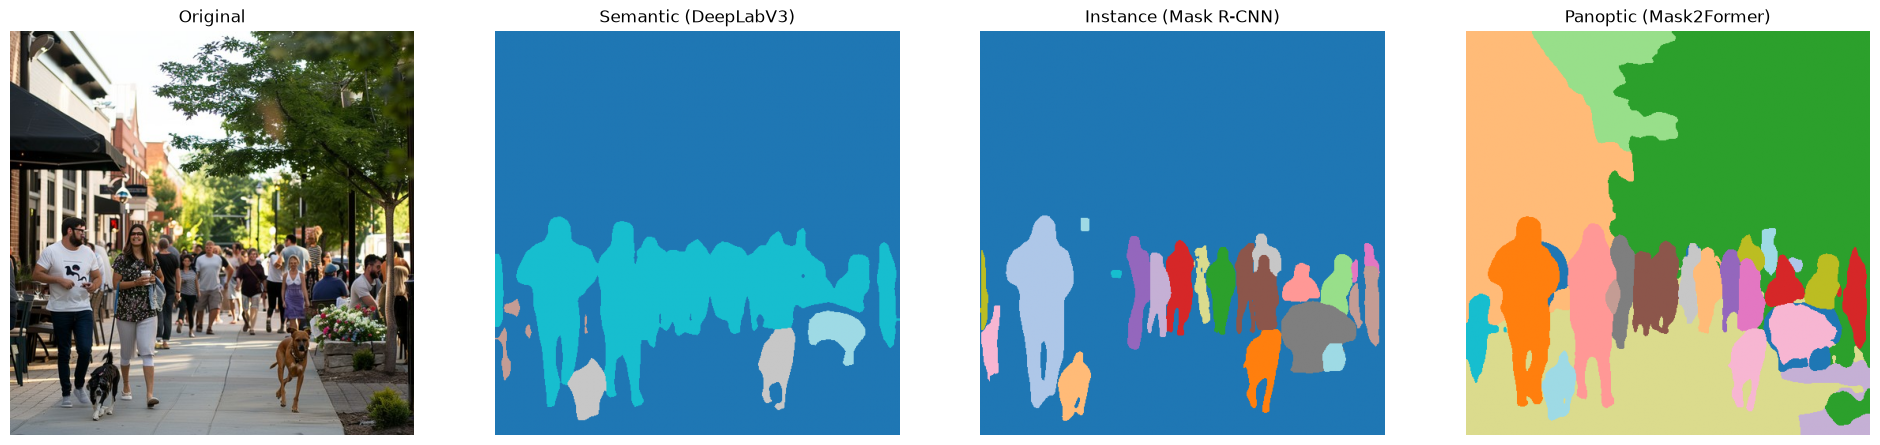

In [ ]:
img_pil = Image.open("assets/StockCake-Sidewalk_Dog_Walk-1091895-medium.jpg").convert("RGB")

# Semantic: DeepLabV3
sem_weights = torchvision.models.segmentation.DeepLabV3_ResNet50_Weights.COCO_WITH_VOC_LABELS_V1
semantic_model = torchvision.models.segmentation.deeplabv3_resnet50(weights=sem_weights).eval()
with torch.no_grad():
    sem_logits = semantic_model(sem_weights.transforms()(img_pil).unsqueeze(0))["out"]  # сама модель не нормализует
semantic_map = sem_logits.argmax(1)[0]

# Instance: Mask R-CNN
inst_weights = torchvision.models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
instance_model = torchvision.models.detection.maskrcnn_resnet50_fpn(weights=inst_weights).eval()
with torch.no_grad():
    inst_out = instance_model([T.functional.to_tensor(img_pil)])[0]

keep = inst_out["scores"] > 0.7
masks = inst_out["masks"][keep, 0] > 0.5  # бинаризуем soft-маски
instance_map = torch.zeros(img_pil.height, img_pil.width, dtype=torch.long)
for idx, m in enumerate(masks, start=1):
    instance_map[m] = idx

# Panoptic: Mask2Former
processor = AutoImageProcessor.from_pretrained("facebook/mask2former-swin-tiny-coco-panoptic")
panoptic_model = Mask2FormerForUniversalSegmentation.from_pretrained(
    "facebook/mask2former-swin-tiny-coco-panoptic"
).eval()
with torch.no_grad():
    outputs = panoptic_model(**processor(images=img_pil, return_tensors="pt"))
panoptic_map = processor.post_process_panoptic_segmentation(
    outputs, target_sizes=[(img_pil.height, img_pil.width)]
)[0]["segmentation"]

voc_classes = sem_weights.meta["categories"]
print("Semantic: классы на картинке:", [voc_classes[c] for c in semantic_map.unique().tolist()])
print("Instance: объектов со score > 0.7:", len(masks))
print("Panoptic: сегментов:", len(panoptic_map.unique()))

fig, axs = plt.subplots(1, 4, figsize=(24, 6))
for ax, im, title in zip(
    axs,
    [img_pil, semantic_map, instance_map, panoptic_map],
    ["Original", "Semantic (DeepLabV3)", "Instance (Mask R-CNN)", "Panoptic (Mask2Former)"],
):
    ax.imshow(im if title == "Original" else im.numpy(), cmap="tab20")
    ax.set_title(title)
    ax.axis("off")

## 2. Метрики сегментации

### 2.0 Главное отличие от детекции:

- Сегментация оценивает качество на **уровне пикселя**.  
- Детекция оценивает качество на **уровне объекта** (bounding box).

Если представить маску класса как бинарное изображение:  

- 1 — пиксель принадлежит классу  
- 0 — пиксель не принадлежит классу
- Маска предсказания обычно бинаризована по трешходу, но может быть и в виде вероятностей (soft)

$$
\text{mask}_{pred} = (\text{mask}_{probs} > threshold).float()
$$


Тогда **пересечение (intersection)** можно посчитать как поэлементное **умножение** масок:  

$$
\text{Intersection} = \text{mask}_{pred} \cdot \text{mask}_{gt}
$$

А **объединение (union)** — как поэлементную **сумму** масок с вычитанием пересечения:

$$
\text{Union} = \text{mask}_{pred} + \text{mask}_{gt} - \text{mask}_{pred} \cdot \text{mask}_{gt}
$$


### 2.1 IoU (Jaccard)

$$
\text{IoU} = \frac{\text{Intersection}}{\text{Union}} = \frac{TP}{TP + FP + FN}
$$

- $TP$ — пиксели класса, предсказанные верно; $FP$ — лишние пиксели; $FN$ — пропущенные пиксели.
- Чувствителен к **маленьким объектам**: ошибка в несколько пикселей на границе маленького объекта сильно роняет IoU (см. пример ниже).

### 2.2 Dice (F1 для сегментации)

$$
\text{Dice} = \frac{2 \cdot TP}{2 \cdot TP + FP + FN} = \frac{2 \sum (\text{mask}_{pred} \cdot \text{mask}_{gt})}{\sum \text{mask}_{pred} + \sum \text{mask}_{gt}},
\qquad
\text{Dice} = \frac{2 \cdot \text{IoU}}{1 + \text{IoU}}
$$

Связь точная для одной пары масок, но **не** для средних по классам/картинкам: mean Dice $\ne$ f(mean IoU).

### 2.3 Pixel Accuracy

$$
\text{Pixel Accuracy} = \frac{\text{число верно классифицированных пикселей}}{\text{общее число пикселей}}
$$

Чувствительна к балансу классов.

### 2.4 mIoU и PQ

- **mIoU** — основная метрика semantic segmentation: IoU считается для каждого класса, затем усредняется по классам. Обычно TP/FP/FN **копятся по всему датасету** (dataset-mIoU, так считают mmsegmentation и бенчмарки), а не усредняются по картинкам.
- **PQ (Panoptic Quality)** — метрика panoptic segmentation;
  $PQ = \underbrace{\frac{\sum_{TP} IoU}{|TP|}}_{SQ} \times \underbrace{\frac{|TP|}{|TP| + \frac12|FP| + \frac12|FN|}}_{RQ}$
    - Предсказанный и GT-сегменты сопоставляются, если IoU > 0.5 (такое сопоставление однозначно),
    - **SQ (Segmentation Quality)** — средний IoU по совпавшим парам, насколько точно очерчены границы
    - **RQ (Recognition Quality)** — F1 по сегментам, насколько хорошо находим объекты
    - PQ считается по каждому классу отдельно и затем усредняется.

In [ ]:
def segmentation_stats(mask_pred: Tensor, mask_gt: Tensor, threshold: float = 0.5) -> tuple[Tensor, Tensor, Tensor]:
    mask_pred = (mask_pred > threshold).float()
    mask_gt = mask_gt.float()
    tp = (mask_pred * mask_gt).sum()
    fp = (mask_pred * (1 - mask_gt)).sum()
    fn = ((1 - mask_pred) * mask_gt).sum()
    return tp, fp, fn


def iou_score(mask_pred: Tensor, mask_gt: Tensor, threshold: float = 0.5, eps: float = 1e-7) -> Tensor:
    tp, fp, fn = segmentation_stats(mask_pred, mask_gt, threshold)
    return tp / (tp + fp + fn + eps)


def dice_score(mask_pred: Tensor, mask_gt: Tensor, threshold: float = 0.5, eps: float = 1e-7) -> Tensor:
    tp, fp, fn = segmentation_stats(mask_pred, mask_gt, threshold)
    return 2 * tp / (2 * tp + fp + fn + eps)


def pixel_accuracy(mask_pred: Tensor, mask_gt: Tensor, threshold: float = 0.5) -> Tensor:
    return ((mask_pred > threshold).float() == mask_gt.float()).float().mean()


def square_mask(size: int, top: int, left: int, side: int) -> Tensor:
    m = torch.zeros(size, size)
    m[top:top + side, left:left + side] = 1
    return m


# Одна и та же ошибка — сдвиг маски на 3 пикселя — для большого и маленького объекта
for side in [100, 10]:
    gt = square_mask(256, 50, 50, side)
    pred = square_mask(256, 53, 53, side)
    iou, dice = iou_score(pred, gt), dice_score(pred, gt)
    print(
        f"объект {side:>3}x{side:<3} | IoU={iou:.3f}  Dice={dice:.3f}  2IoU/(1+IoU)={2 * iou / (1 + iou):.3f}  "
        f"PixelAcc={pixel_accuracy(pred, gt):.4f}"
    )

объект 100x100 | IoU=0.888  Dice=0.941  2IoU/(1+IoU)=0.941  PixelAcc=0.9820
объект  10x10  | IoU=0.325  Dice=0.490  2IoU/(1+IoU)=0.490  PixelAcc=0.9984


Pixel accuracy почти не реагирует на ошибку для маленького объекта, а IoU/Dice падают в разы.

## 3. Функции потерь для сегментации

### 3.1 Per-pixel losses

Loss считается **для каждого пикселя независимо** и усредняется.

#### Binary Cross-Entropy (BCE)

$$
\text{BCE} = -\frac{1}{N} \sum_{i=1}^{N} \left[y_i \log p_i + (1-y_i)\log(1-p_i) \right],
\qquad y_i \in \{0, 1\},\; p_i = \sigma(z_i)
$$

> На практике используют `nn.BCEWithLogitsLoss`: модель выдаёт **логиты** $z_i$, sigmoid применяется внутри (так численно стабильнее).

#### Cross-Entropy (многоклассовая сегментация)

$$
\text{CE} = -\frac{1}{N} \sum_{i=1}^{N} \sum_{c=1}^{K} y_{i,c}\log p_{i,c}
$$

> В коде one-hot не нужен: `nn.CrossEntropyLoss` принимает логиты `(B, K, H, W)` и **целочисленную** маску `(B, H, W)`.
Пиксели без разметки помечают, например, 255 и исключают через `ignore_index=255`.

#### Focal Loss

Модификация CE для **сильного дисбаланса**: лёгкие пиксели (уверенно и верно классифицированные) почти не дают вклада.

$$
\text{FL}(p_t) = -\alpha_t (1-p_t)^\gamma \log(p_t),
\qquad
p_t = \begin{cases} p_i, & y_i = 1 \\ 1 - p_i, & y_i = 0 \end{cases},
\qquad
\alpha_t = \begin{cases} \alpha, & y_i = 1 \\ 1 - \alpha, & y_i = 0 \end{cases}
$$

- $\gamma \ge 0$ — фокусировка (в статье $\gamma = 2$); $\gamma = 0$ → обычная взвешенная CE;
- $\alpha_t$ — балансировка классов. 

> Фан факт: в статье лучшим оказалось $\alpha = 0.25$, т.е. положительный класс получает *меньший* вес — потому что $\gamma$ уже подавил лёгкие негативы (типа фона).

#### Soft Cross-Entropy

Если разметка **вероятностная** ($\sum_c y_{i,c} = 1$, но $y_{i,c} \in [0, 1]$), формула CE та же, просто $y$ не one-hot.  

Применяется в knowledge distillation (учитель выдаёт распределение), label smoothing (сглаживание gt), semi-supervised (псевдо-разметка).

---

### 3.2 Metric-based losses: Dice и IoU

Хочется оптимизировать сразу метрику: $\text{Loss} = 1 - \text{Dice}$ или $1 - \text{IoU}$.

**Но:** метрики выше считаются по **бинаризованной** маске, а у порога градиент равен нулю почти везде.
Поэтому в loss подставляют **вероятности** без порога — получается **soft Dice / soft IoU**:

$$
\mathcal{L}_{\text{soft Dice}} = 1 - \frac{2 \sum_i p_i g_i + \varepsilon}{\sum_i p_i + \sum_i g_i + \varepsilon},
\qquad
\mathcal{L}_{\text{soft IoU}} = 1 - \frac{\sum_i p_i g_i + \varepsilon}{\sum_i p_i + \sum_i g_i - \sum_i p_i g_i + \varepsilon}
$$

> - Dice/IoU loss нечувствителен к дисбалансу фон/объект, но шумный на маленьких объектах и в начале обучения.
> - На практике почти всегда используют **сумму** BCE (или focal) и Dice: так обучаются U-Net++ (BCE + Dice), Mask2Former (BCE + Dice), SAM (focal + Dice).

In [5]:
def bce_with_logits(logits: Tensor, target: Tensor) -> Tensor:
    # log(sigmoid(z)) и log(1 - sigmoid(z)) = log(sigmoid(-z)) — численно стабильная запись BCE
    return -(target * F.logsigmoid(logits) + (1 - target) * F.logsigmoid(-logits)).mean()


def focal_loss(logits: Tensor, target: Tensor, alpha: float = 0.25, gamma: float = 2.0) -> Tensor:
    p = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, target, reduction="none")
    p_t = p * target + (1 - p) * (1 - target)
    alpha_t = alpha * target + (1 - alpha) * (1 - target)
    return (alpha_t * (1 - p_t) ** gamma * ce).mean()


def soft_dice_loss(logits: Tensor, target: Tensor, eps: float = 1.0) -> Tensor:
    p = torch.sigmoid(logits)
    inter = (p * target).sum(dim=(-2, -1))
    denom = p.sum(dim=(-2, -1)) + target.sum(dim=(-2, -1))
    return (1 - (2 * inter + eps) / (denom + eps)).mean()


target = square_mask(64, 20, 20, 16).unsqueeze(0)  # (1, H, W), объект ~6% площади
logits = torch.randn(1, 64, 64)

print(f"BCE (своя)   : {bce_with_logits(logits, target):.4f}   torch: {F.binary_cross_entropy_with_logits(logits, target):.4f}")
print(f"Focal (своя) : {focal_loss(logits, target):.4f}   torchvision: "
      f"{torchvision.ops.sigmoid_focal_loss(logits, target, alpha=0.25, gamma=2.0, reduction='mean'):.4f}")
print(f"Soft Dice    : {soft_dice_loss(logits, target):.4f}")

# Почему нужен soft-вариант: у "жёсткого" Dice по бинаризованной маске нет градиента
logits.requires_grad_(True)
hard_dice_loss = 1 - dice_score(torch.sigmoid(logits), target)
print("hard Dice requires_grad:", hard_dice_loss.requires_grad)  # False: порог "оборвал" граф
soft_dice_loss(logits, target).backward()
print(f"soft Dice: норма градиента по логитам = {logits.grad.norm():.4f}")

BCE (своя)   : 0.8009   torch: 0.8009
Focal (своя) : 0.2440   torchvision: 0.2440
Soft Dice    : 0.8917
hard Dice requires_grad: False
soft Dice: норма градиента по логитам = 0.0029


### 3.3 Продвинутые loss-функции

#### Tversky Loss

Обобщение Dice, позволяющее по-разному штрафовать FP и FN:

$$
\text{Tversky} = \frac{TP}{TP + \alpha \cdot FP + \beta \cdot FN}, \qquad \text{Tversky Loss} = 1 - \text{Tversky}
$$

- $\alpha$ — штраф за FP, $\beta$ — штраф за FN (TP/FP/FN считаются по вероятностям, как в soft Dice);
- $\alpha = \beta = 0.5$ → Dice; $\alpha = \beta = 1$ → IoU (Jaccard);
- $\beta > \alpha$ (в статье лучше всего $\alpha=0.3, \beta=0.7$) — сильнее штрафуем пропуски: полезно, когда важна полнота.

#### Lovasz Loss (Berman et al., 2018)

Хотим оптимизировать **IoU напрямую**. Jaccard loss $\Delta_J = 1 - \text{IoU}$ — функция от *множества* ошибочных пикселей, и она субмодулярна.
У таких функций есть **расширение Ловаса** — выпуклое кусочно-линейное продолжение на вещественные «ошибки» пикселей. Его и минимизируют.

Lovasz loss — выпуклая дифференцируемая замена Jaccard loss $1-\text{IoU}$: ошибки пикселей сортируются, и каждая взвешивается тем, насколько она увеличивает $1-\text{IoU}$:

$$\mathcal{L}_{\text{Lovász}} = \sum_i m_{(i)}\, g_i$$

**Алгоритм (бинарный случай, Lovфsz hinge):**

1. Модель выдаёт **логиты** $s_i \in \mathbb{R}$, метки переводим в $y^*_i \in \{-1, +1\}$.  
   Ошибка пикселя — hinge: $m_i = \max(0,\; 1 - s_i \, y^*_i)$. Она равна 0, только если пиксель классифицирован верно **с запасом** (margin $\ge 1$).
2. Сортируем ошибки по убыванию: $m_{(1)} \ge m_{(2)} \ge \dots \ge m_{(N)}$.
3. Вес $i$-го пикселя — насколько вырастет Jaccard loss, если к ошибкам добавить $i$-й пиксель:
   $$
   g_i = \Delta_J(\{(1), \dots, (i)\}) - \Delta_J(\{(1), \dots, (i-1)\})
   $$
   где $\Delta_J(M)$ — это $1 - \text{IoU}$, если считать пиксели из $M$ ошибочно предсказанными.
4. $\mathcal{L}_{\text{Lovász}} = \sum_{i=1}^{N} m_{(i)} \, g_i$

**Lovasz-Softmax** (многоклассовый): для класса $c$ ошибка $m_i(c) = |y_{i,c} - p_{i,c}|$ (здесь уже вероятности после softmax), считаем loss для каждого класса и усредняем по классам


**Особенности:**
- оптимизирует именно IoU-подобную величину, а не попиксельную точность — помогает на мелких объектах и при дисбалансе;
- loss считается по картинке или по батчу — это аппроксимирует image-mIoU или dataset-mIoU соответственно;
> Часто используют на этапе дообучения после CE/BCE. Готовые реализации: официальный репозиторий авторов, `smp.losses.LovaszLoss`.

In [ ]:
def tversky_loss(logits: Tensor, target: Tensor, alpha: float = 0.3, beta: float = 0.7, eps: float = 1e-7) -> Tensor:
    p = torch.sigmoid(logits)
    tp = (p * target).sum()
    fp = (p * (1 - target)).sum()
    fn = ((1 - p) * target).sum()
    return 1 - tp / (tp + alpha * fp + beta * fn + eps)


# Lovasz hinge ~ github.com/bermanmaxim/LovaszSoftmax
def lovasz_grad(gt_sorted: Tensor) -> Tensor:
    # g_i = Δ_J(первые i пикселей ошибочны) - Δ_J(первые i-1)
    gts = gt_sorted.sum()
    intersection = gts - gt_sorted.cumsum(0)        # сколько объекта останется "угаданным"
    union = gts + (1 - gt_sorted).cumsum(0)         # объект + фон, ошибочно отнесённый к объекту
    jaccard = 1.0 - intersection / union            # Δ_J для каждого префикса
    jaccard[1:] = jaccard[1:] - jaccard[:-1]        # разности соседних префиксов
    return jaccard


def lovasz_hinge(logits: Tensor, target: Tensor) -> Tensor:
    logits, target = logits.reshape(-1), target.reshape(-1).float()
    signs = 2.0 * target - 1.0
    errors = 1.0 - logits * signs                   # hinge-ошибки на логитах
    errors_sorted, perm = torch.sort(errors, descending=True)
    grad = lovasz_grad(target[perm])
    return torch.dot(F.relu(errors_sorted), grad)


print(f"Tversky: {tversky_loss(logits.detach(), target):.4f}")
print(f"Lovász (случайные логиты): {lovasz_hinge(logits.detach(), target):.4f}")
print(f"Lovász (идеальные логиты, margin 5): {lovasz_hinge(10 * target - 5, target):.4f}")

# Свойство расширения Ловаса: на "жёстких" ошибках (0/1) оно совпадает с самим Jaccard loss
hard_logits = torch.where(torch.rand(1, 64, 64) < 0.9, 2 * target - 1, 1 - 2 * target)  # 10% пикселей "перевёрнуто"
lovasz_on_hard = lovasz_hinge(hard_logits, target)
jaccard_loss = 1 - iou_score(torch.sigmoid(hard_logits), target)
print(f"logits = ±1, hinge-ошибки ∈ {{0, 2}}: Lovász / 2 = {lovasz_on_hard / 2:.4f},  1 - IoU = {jaccard_loss:.4f}")

# Готовые реализации: smp.losses.LovaszLoss(mode="binary") (per_image=False по умолчанию)
print(f"smp LovaszLoss: {smp.losses.LovaszLoss(mode='binary')(logits.detach().unsqueeze(0), target.unsqueeze(0)):.4f}")

Tversky: 0.8435
Lovász (случайные логиты): 2.4555
Lovász (идеальные логиты, margin 5): 0.0000
logits = ±1, hinge-ошибки ∈ {0, 2}: Lovász / 2 = 0.6413,  1 - IoU = 0.6413
smp LovaszLoss: 2.4555


## 4. Семантическая сегментация: архитектуры

Основные подходы — **encoder–decoder**: encoder (обычно backbone классификатора) постепенно уменьшает разрешение и "достает" семантику, decoder восстанавливает разрешение.   

Различаются в основном тем, **как объединяют признаки разных масштабов**.

## 4.1 U-Net (Ronneberger et al., 2015)

![unet_nn](assets/u-net-architecture.png)

**Идея:** объединить **глобальный контекст** (что изображено) и **точную локализацию** (где именно) через **skip connections**
между уровнями encoder и decoder одинакового масштаба.

```
Input ─► [Encoder] ─► Bottleneck ─► [Decoder] ─► Output
             │                          ▲
             └──── skip connections ────┘
```

#### Encoder (downsampling path)

Уровень encoder: `Conv 3×3 → ReLU → Conv 3×3 → ReLU → MaxPool 2×2`

$$
x_l = F_l(x_{l-1}^{down})
$$

где $F_l(\cdot)$ — **ConvBlock**: 
$$
F_l(x) = \text{ReLU}(\text{Conv}_{3\times3}(\text{ReLU}(\text{Conv}_{3\times3}(x))))
$$

После каждого блока выполняется downsampling:

$$
x_{l}^{down} = Pool(x_l)
$$
```
H × W × 3  →  H × W × 64  →  H/2 × W/2 × 128  →  H/4 × W/4 × 256  →  H/8 × W/8 × 512  →  bottleneck: H/16 × W/16 × 1024
```

#### Decoder (upsampling path)

Уровень decoder: `Upsample (ConvTranspose 2×2) → concat(skip) → Conv 3×3 → ReLU → Conv 3×3 → ReLU`

$$
x_l^{dec} = F_l\big([x_l^{enc},\; \text{Up}(x_{l+1}^{dec})]\big)
$$

где $[\cdot, \cdot]$ — **конкатенация по каналам**. Skip connections возвращают в decoder высокочастотные детали, потерянные при pooling, дают точные границы.

> В оригинальной статье ConvTranspose, но на практике чаще Upsample + Conv (в `smp` вроде так)
> В оригинальной статье cвёртки без padding: выход меньше входа, поэтому признаки encoder перед конкатенацией обрезаются. Сейчас почти всегда ставят `padding=1` — выход того же размера

Финальный слой — `Conv 1×1` в $C$ каналов → выход $H \times W \times C$, затем softmax / sigmoid (или сразу `CrossEntropyLoss` / `BCEWithLogitsLoss` на логитах).


#### Плюсы и минусы
- `+` точная локализация, простая и стабильная архитектура, хорошо работает на **небольших датасетах**, стандарт в medical imaging
- `-` ограниченный receptive field и мультимасштабный контекст; skip connections соединяют только уровни одного масштаба, а признаки encoder и decoder находятся на разных «уровнях абстракции» (*semantic gap*)

Дальнейшие улучшения: **FPN / PAN** (мультимасштабность), **U-Net++** (вложенные skip connections), **U²-Net** (U-Net внутри блоков), **DeepLab v3** (atrous conv + ASPP).

In [7]:
def count_trainable_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


class ConvBlock(nn.Module):
    # Conv 3x3 -> ReLU -> Conv 3x3 -> ReLU (padding=1: размер не меняется)

    def __init__(self, in_channels: int, out_channels: int) -> None:
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.block(x)


class UNet(nn.Module):
    def __init__(self, in_channels: int, num_classes: int) -> None:
        super().__init__()
        self.enc1, self.enc2 = ConvBlock(in_channels, 64), ConvBlock(64, 128)
        self.enc3, self.enc4 = ConvBlock(128, 256), ConvBlock(256, 512)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(512, 1024)
        self.up4, self.dec4 = nn.ConvTranspose2d(1024, 512, 2, stride=2), ConvBlock(1024, 512)
        self.up3, self.dec3 = nn.ConvTranspose2d(512, 256, 2, stride=2), ConvBlock(512, 256)
        self.up2, self.dec2 = nn.ConvTranspose2d(256, 128, 2, stride=2), ConvBlock(256, 128)
        self.up1, self.dec1 = nn.ConvTranspose2d(128, 64, 2, stride=2), ConvBlock(128, 64)
        self.final_conv = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x: Tensor) -> Tensor:
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([e4, self.up4(b)], dim=1))
        d3 = self.dec3(torch.cat([e3, self.up3(d4)], dim=1))
        d2 = self.dec2(torch.cat([e2, self.up2(d3)], dim=1))
        d1 = self.dec1(torch.cat([e1, self.up1(d2)], dim=1))
        return self.final_conv(d1)


x = torch.randn(2, 3, 256, 256)  # H, W должны делиться на 16 (4 pooling)
model_unet = UNet(3, 2)
print("U-Net output:", model_unet(x).shape, f"| params: {count_trainable_params(model_unet):,}")

# То же самое из библиотеки, но с предобученным encoder (ResNet34) вместо обучаемого с нуля
model_smp_unet = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=2)
print("smp.Unet(resnet34) output:", model_smp_unet(x).shape, f"| params: {count_trainable_params(model_smp_unet):,}")

U-Net output: torch.Size([2, 2, 256, 256]) | params: 31,031,810


smp.Unet(resnet34) output: torch.Size([2, 2, 256, 256]) | params: 24,436,514


## 4.2 Feature Pyramid Network (FPN, Lin et al., 2017)

**Идея:** строить пирамиду признаков разных масштабов и использовать их одновременно.

![fpn](assets/fpn.png)

**Проблема:** ранние слои CNN — высокое разрешение, но мало семантики; поздние — наоборот. Использовать только последний уровень — терять детали.

**Bottom-up pathway** — обычный backbone, признаки $C_2, \dots, C_5$:

| уровень | $C_2$ | $C_3$ | $C_4$ | $C_5$ |
|---|---|---|---|---|
| разрешение | $H/4$ | $H/8$ | $H/16$ | $H/32$ |

**Top-down pathway + lateral connections** — семантика распространяется от глубоких уровней к мелким:

$$
M_5 = \text{Conv}_{1\times1}(C_5), \qquad
M_l = \text{Conv}_{1\times1}(C_l) + \text{Up}_{\times 2}(M_{l+1}), \qquad
P_l = \text{Conv}_{3\times3}(M_l)
$$

- $\text{Conv}_{1\times1}$ (lateral) выравнивает число каналов (в статье $d = 256$);
- $\text{Up}_{\times 2}$ — nearest upsampling, $+$ — поэлементная сумма;
- $\text{Conv}_{3\times3}$ применяется к каждой сумме, чтобы уменьшить aliasing после upsampling. Рекурсия идёт по $M_l$ (до сглаживания) — так в оригинале и в detectron2.

Итог: каждый уровень $P_l$ = **детали** своего масштаба + **семантика** из глубоких слоёв.

#### FPN для семантической сегментации (Panoptic FPN, Kirillov et al., 2019)

Сам FPN — это «шея» для детекции. Голова для сегментации из Panoptic FPN:

```
P2 (1/4)  P3 (1/8)  P4 (1/16)  P5 (1/32)
   │         │         │          │      каждый уровень: [Conv3×3 → GN → ReLU → Up×2] 
   |         |         |          |          нужное число раз, до 1/4 (размерности P2)
   └─────────┴────┬────┴──────────┘
                  Σ   поэлементная сумма (concat в статье давал то же качество)
                  │
             Conv 1×1 → Up×4 → маска H×W
```

| | U-Net | FPN |
|---|---|---|
| объединение | concat + conv-блок | sum |
| decoder | отдельный «тяжёлый» decoder | лёгкая пирамида, $d$ каналов на всех уровнях |
| выходы | один | пирамида признаков (удобно для детекции) |

Развитие идеи: **PAN** (добавляет bottom-up путь), **BiFPN** (EfficientDet: обучаемые веса при слиянии масштабов).

In [8]:
# Признаки backbone разных масштабов: smp-энкодер возвращает список карт [x, C1, C2, C3, C4, C5]
encoder = smp.encoders.get_encoder("resnet34", weights=None)
feats = encoder(torch.randn(1, 3, 256, 256))
for name, f in zip(["input", "C1", "C2", "C3", "C4", "C5"], feats):
    print(f"{name:>5}: {tuple(f.shape)}  stride={256 // f.shape[-1]}")


class FPNTopDown(nn.Module):
    # Top-down путь FPN: M_l = lateral(C_l) + Up(M_{l+1}),  P_l = smooth(M_l)

    def __init__(self, in_channels: list[int], d: int = 256) -> None:
        super().__init__()
        self.lateral = nn.ModuleList([nn.Conv2d(c, d, 1) for c in in_channels])
        self.smooth = nn.ModuleList([nn.Conv2d(d, d, 3, padding=1) for _ in in_channels])

    def forward(self, features: list[Tensor]) -> list[Tensor]:  # features: [C2, C3, C4, C5]
        m = self.lateral[-1](features[-1])
        outs = [self.smooth[-1](m)]
        for i in range(len(features) - 2, -1, -1):
            m = self.lateral[i](features[i]) + F.interpolate(m, size=features[i].shape[-2:], mode="nearest")
            outs.insert(0, self.smooth[i](m))
        return outs  # [P2, P3, P4, P5]


fpn = FPNTopDown(in_channels=encoder.out_channels[2:])
pyramid = fpn(feats[2:])
print("FPN:", [tuple(p.shape) for p in pyramid])

# Готовая модель: encoder + FPN + голова Panoptic FPN (слияние — сумма, decoder_merge_policy="add")
model_fpn = smp.FPN(encoder_name="resnet34", encoder_weights=None, classes=1)
print("smp.FPN output:", model_fpn(torch.randn(1, 3, 256, 256)).shape, f"| params: {count_trainable_params(model_fpn):,}")

input: (1, 3, 256, 256)  stride=1
   C1: (1, 64, 128, 128)  stride=2
   C2: (1, 64, 64, 64)  stride=4
   C3: (1, 128, 32, 32)  stride=8
   C4: (1, 256, 16, 16)  stride=16
   C5: (1, 512, 8, 8)  stride=32
FPN: [(1, 256, 64, 64), (1, 256, 32, 32), (1, 256, 16, 16), (1, 256, 8, 8)]


smp.FPN output: torch.Size([1, 1, 256, 256]) | params: 23,155,393


## 4.3 Path Aggregation Network (PANet, Liu et al., 2018)

![pan](assets/pan.png)

В FPN семантика идёт **сверху вниз**, но путь «деталей» от $C_2$ к верхним уровням длинный — через весь backbone (сотни слоёв).
PANet (статья про instance segmentation) добавляет **короткий bottom-up путь** поверх FPN:

```
Encoder:    C2 → C3 → C4 → C5
Top-down:   P2 ← P3 ← P4 ← P5          (FPN, семантика ↓)
Bottom-up:  N2 → N3 → N4 → N5          (PAN, детали ↑)
```

$$
N_2 = P_2, \qquad
N_{l+1} = \text{Conv}_{3\times3}\big(\text{Conv}_{3\times3,\ stride=2}(N_l) + P_{l+1}\big)
$$

| путь | что передаёт |
|---|---|
| top-down (FPN) | семантику |
| bottom-up (PAN) | локализацию, детали |

Ещё одна идея статьи — **adaptive feature pooling**: признаки RoI собираются со **всех** уровней пирамиды и сливаются (max), а не с одного уровня, как в FPN.

Наследники: «PAN-neck» в YOLOv4/YOLOv5 и далее, **BiFPN** (EfficientDet) — многократные двусторонние слияния с обучаемыми весами.

> `smp.PAN` — это **другая** архитектура (*Pyramid Attention Network*, Li et al., 2018), не PANet. Поэтому bottom-up путь ниже написан вручную.

In [9]:
class PANBottomUp(nn.Module):
    # N_2 = P_2,  N_{l+1} = Conv3x3( Conv3x3_stride2(N_l) + P_{l+1} )

    def __init__(self, num_levels: int = 4, d: int = 256) -> None:
        super().__init__()
        self.down = nn.ModuleList([nn.Conv2d(d, d, 3, stride=2, padding=1) for _ in range(num_levels - 1)])
        self.fuse = nn.ModuleList([nn.Conv2d(d, d, 3, padding=1) for _ in range(num_levels - 1)])

    def forward(self, pyramid: list[Tensor]) -> list[Tensor]:  # pyramid: [P2, P3, P4, P5]
        outs = [pyramid[0]]
        for i, p in enumerate(pyramid[1:]):
            outs.append(F.relu(self.fuse[i](self.down[i](outs[-1]) + p)))
        return outs  # [N2, N3, N4, N5]


pan = PANBottomUp()
print("PAN:", [tuple(n.shape) for n in pan(pyramid)])

PAN: [(1, 256, 64, 64), (1, 256, 32, 32), (1, 256, 16, 16), (1, 256, 8, 8)]


## 4.4 U-Net++ (Zhou et al., 2018)

**Мотивация — semantic gap:** в U-Net skip connection склеивает «сырые» низкоуровневые признаки encoder с высокоуровневыми признаками decoder.
U-Net++ заменяет прямой skip на **плотную цепочку промежуточных conv-блоков**, которые постепенно «досемантизируют» признаки encoder.

![unet_++](assets/unet++.png)

#### Обозначения

![unet_++](assets/unet++_2.jpg)

$X^{i,j}$: $i$ — уровень (номер downsampling, строка), $j$ — номер узла на skip-пути (столбец).
$X^{i,0}$ — encoder, $X^{0,j}$ — верхний ряд, из которого делается предсказание. В статье сеть 5-уровневая, верхний ряд — до $X^{0,4}$:

```
X0,0  X0,1  X0,2  X0,3  X0,4
X1,0  X1,1  X1,2  X1,3
X2,0  X2,1  X2,2
X3,0  X3,1
X4,0
```

#### Формула узла

$$
X^{i,j} =
\begin{cases}
H\big(X^{i-1,j}\big), & j = 0 \quad \text{(encoder, после downsampling)} \\
H\Big(\big[X^{i,0}, X^{i,1}, \dots, X^{i,j-1},\ \text{Up}(X^{i+1,j-1})\big]\Big), & j > 0
\end{cases}
$$

$H$ — conv-блок, $[\cdot]$ — конкатенация: каждый узел видит **все** предыдущие узлы своего уровня (dense-связи) и upsample узла уровнем ниже.

#### Deep Supervision

Каждый узел верхнего ряда $X^{0,1}, \dots, X^{0,4}$ — полноценный выход ($1\times1$ conv + sigmoid). Loss — сумма по всем выходам (в статье BCE + Dice):
$\mathcal{L} = \sum_{k=1}^{4} \mathcal{L}(\hat{Y}_k, Y)$.

Два режима инференса:
1. **accurate mode** — усредняем все выходы;
2. **fast mode** — берём один выход $X^{0,k}$ и **отрезаем** (pruning) всё, что правее: модель становится меньше и быстрее.

> В `smp.UnetPlusPlus` deep supervision нет — только один выход.

## 4.5 U²-Net (Qin et al., 2020)

![u2net](assets/u2net.png)

Предложена для **salient object detection** (выделить главный объект на картинке), популярна для удаления фона.

**Идея:** U-Net, у которого **каждый блок — сам маленький U-Net**. Блок RSU-L (Residual U-block) глубины $L$:

```
x ─► F1 = Conv(x) ─► mini U-Net глубины L (encoder–decoder внутри блока) ─► (+) ─► выход
                 └──────────────────────────────────────────────────────────┘
```

$$
H_{RSU}(x) = \mathcal{U}(F_1(x)) + F_1(x)
$$

Residual берётся не от входа, а от выхода первой свёртки $F_1$. Каждый блок сам по себе извлекает **мультимасштабные** признаки.

- Encoder: RSU-7 → RSU-6 → RSU-5 → RSU-4 → RSU-4F → RSU-4F (число — глубина мини-U-Net; «F» — вместо pooling используются dilated conv, т.к. разрешение уже маленькое);
- decoder симметричный;
- **6 side outputs** (со всех уровней decoder + самого глубокого) → upsample → concat → $1\times1$ conv + sigmoid = итоговая маска; loss (BCE) — сумма по всем side outputs и итоговой маске.

| модель | что улучшает |
|---|---|
| U-Net | encoder–decoder + skip connections |
| U-Net++ | сами skip connections (nested, dense) |
| U²-Net | сами блоки сети (U-Net внутри блока) |

In [10]:
model_unetpp = smp.UnetPlusPlus(encoder_name="resnet34", encoder_weights=None, classes=1)
print("smp.UnetPlusPlus output:", model_unetpp(torch.randn(1, 3, 256, 256)).shape,
      f"| params: {count_trainable_params(model_unetpp):,}")

smp.UnetPlusPlus output: torch.Size([1, 1, 256, 256]) | params: 26,078,609


## 4.6 DeepLab v3 (Chen et al., 2017)

![deeplab_v3](assets/deeplab_v3.png)

**Идея:** захватить контекст на разных масштабах, **не теряя разрешения** feature map.

#### Atrous (dilated) convolution

Между весами ядра вставляются «дырки» — receptive field растёт без роста числа параметров и без downsampling:

$$
y[i] = \sum_{k=1}^{K} x[i + r \cdot k] \cdot w[k]
$$

$r$ — rate (dilation); $r = 1$ — обычная свёртка; ядро $3\times3$ с $r=2$ «видит» $5\times5$, с $r=3$ — $7\times7$.

#### Output stride

Обычный ResNet уменьшает картинку в 32 раза (output stride = 32). В DeepLab v3 на последнем блоке **stride заменяют на dilation**:
output stride = 16 (или 8 — дороже, но точнее). Карта признаков остаётся крупнее при том же receptive field.

#### ASPP (Atrous Spatial Pyramid Pooling)

Параллельные ветви поверх последней карты признаков:

```
                     feature map (output stride 16)
     ┌──────────┬──────────┼──────────┬──────────────┐
  Conv 1×1   Conv 3×3   Conv 3×3   Conv 3×3   Image pooling (GAP → Conv 1×1 → Upsample)
             rate=6     rate=12    rate=18
     └──────────┴──────────┼──────────┴──────────────┘
                  Concat → Conv 1×1 (256) → Conv 1×1 (classes) → Upsample ×16
```

- rates (6, 12, 18) — для output stride 16; для output stride 8 их **удваивают**;
- если rate сравним с размером карты признаков, ядро $3\times3$ **вырождается в $1\times1$** (остальные веса попадают в padding) — поэтому важно и output stride, и ветка image pooling для глобального контекста.

#### DeepLab v3+ (2018): лёгкий decoder

1. ASPP-выход → upsample ×4 (до 1/4);
2. low-level признаки encoder (stride 4) → $1\times1$ conv до 48 каналов;
3. concat → две $3\times3$ conv (256) → upsample ×4 до $H \times W$.

#### Плюсы и минусы
- `+` сильный мультимасштабный контекст, гибкая настройка receptive field через rates
- `-` дорого: свёртки на карте 1/16 (1/8) вместо 1/32; без decoder (v3) границы грубые; в v3 нет skip connections — это и исправляет v3+

In [11]:
class ASPP(nn.Module):
    def __init__(self, in_channels: int, out_channels: int = 256, rates: tuple[int, ...] = (6, 12, 18)) -> None:
        super().__init__()

        def conv_bn_relu(kernel_size: int, dilation: int = 1) -> nn.Sequential:
            padding = 0 if kernel_size == 1 else dilation
            return nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size, padding=padding, dilation=dilation, bias=False),
                nn.BatchNorm2d(out_channels),
                nn.ReLU(inplace=True),
            )

        self.branches = nn.ModuleList([conv_bn_relu(1)] + [conv_bn_relu(3, r) for r in rates])
        # BatchNorm на карте 1x1 не работает при batch_size=1, поэтому в image pooling его нет
        self.image_pool = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(in_channels, out_channels, 1), nn.ReLU())
        self.project = nn.Sequential(
            nn.Conv2d(out_channels * (len(rates) + 2), out_channels, 1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x: Tensor) -> Tensor:
        outs = [branch(x) for branch in self.branches]
        outs.append(F.interpolate(self.image_pool(x), size=x.shape[-2:], mode="bilinear", align_corners=False))
        return self.project(torch.cat(outs, dim=1))


# Output stride: обычный ResNet vs ResNet с dilation в последнем блоке (как в DeepLab v3)
x = torch.randn(1, 3, 512, 512)
for replace in [[False, False, False], [False, False, True]]:
    backbone = torchvision.models.resnet50(weights=None, replace_stride_with_dilation=replace)
    body = nn.Sequential(*list(backbone.children())[:-2])
    f = body(x)
    print(f"replace_stride_with_dilation={replace}: {tuple(f.shape)}, output stride = {512 // f.shape[-1]}")

aspp = ASPP(in_channels=2048).eval()
print("ASPP output:", aspp(f).shape)

# Готовые модели: torchvision.models.segmentation.deeplabv3_resnet50, smp.DeepLabV3, smp.DeepLabV3Plus
model_dlv3p = smp.DeepLabV3Plus(encoder_name="resnet34", encoder_weights=None, classes=1).eval()  # eval: BN в image pooling не работает на batch=1
print("smp.DeepLabV3Plus output:", model_dlv3p(torch.randn(1, 3, 256, 256)).shape,
      f"| params: {count_trainable_params(model_dlv3p):,}")

replace_stride_with_dilation=[False, False, False]: (1, 2048, 16, 16), output stride = 32


replace_stride_with_dilation=[False, False, True]: (1, 2048, 32, 32), output stride = 16
ASPP output: torch.Size([1, 256, 32, 32])


smp.DeepLabV3Plus output: torch.Size([1, 1, 256, 256]) | params: 22,437,457


## 4.7 Как это обучать на практике

Минимальный рабочий пайплайн бинарной сегментации — его же можно взять за основу для ДЗ.

**Данные:** [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/) — фото кошек и собак с trimap-разметкой
(1 — животное, 2 — фон, 3 — граница). Скачивается через `torchvision` (≈ 800 МБ в папку `data/`).
Считаем маской «животное + граница».

**На что обратить внимание:**
- маску ресайзим **nearest**-интерполяцией: bilinear создаст промежуточные значения, и после порога маска «распухнет»;
- encoder предобучен на ImageNet → вход **нормализуем** теми же mean/std;
- loss: BCE + soft Dice (`smp.losses.DiceLoss`); метрика: IoU, TP/FP/FN копятся по всей валидации;
- фиксируем seed разбиения, иначе результаты невоспроизводимы.

In [12]:
from torch.utils.data import DataLoader, Dataset, Subset

IMAGENET_MEAN, IMAGENET_STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)


class PetsBinary(Dataset):
    def __init__(self, root: str = "data", size: int = 256) -> None:
        self.ds = torchvision.datasets.OxfordIIITPet(root, split="trainval", target_types="segmentation", download=True)
        self.img_tf = T.Compose([T.Resize((size, size)), T.ToTensor(), T.Normalize(IMAGENET_MEAN, IMAGENET_STD)])
        self.mask_tf = T.Resize((size, size), interpolation=T.InterpolationMode.NEAREST)

    def __len__(self) -> int:
        return len(self.ds)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        image, trimap = self.ds[idx]
        mask = torch.from_numpy(np.array(self.mask_tf(trimap)) != 2).float().unsqueeze(0)  # (1, H, W)
        return self.img_tf(image), mask


dataset = PetsBinary()
perm = torch.randperm(len(dataset), generator=torch.Generator().manual_seed(42))
train_ds, val_ds = Subset(dataset, perm[:1500].tolist()), Subset(dataset, perm[1500:1900].tolist())  # подмножество ради скорости
train_loader = DataLoader(train_ds, batch_size=16, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=16)
print(f"всего: {len(dataset)}, train: {len(train_ds)}, val: {len(val_ds)}")

всего: 3680, train: 1500, val: 400


In [13]:
def evaluate_iou(model: nn.Module, loader: DataLoader) -> float:
    model.eval()
    tp = fp = fn = 0.0
    with torch.no_grad():
        for images, masks in loader:
            preds = (model(images.to(device)) > 0).float().cpu()  # логит > 0  <=>  sigmoid > 0.5
            tp += (preds * masks).sum().item()
            fp += (preds * (1 - masks)).sum().item()
            fn += ((1 - preds) * masks).sum().item()
    return tp / (tp + fp + fn)


model = smp.Unet(encoder_name="resnet34", encoder_weights="imagenet", classes=1).to(device)
bce, dice = nn.BCEWithLogitsLoss(), smp.losses.DiceLoss(mode="binary")
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)

EPOCHS = 3
for epoch in range(EPOCHS):
    model.train()
    start, total_loss = time.time(), 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        loss = bce(logits, masks) + dice(logits, masks)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"epoch {epoch + 1}/{EPOCHS} | train loss {total_loss / len(train_loader):.4f} | "
          f"val IoU {evaluate_iou(model, val_loader):.4f} | {time.time() - start:.0f}s")

epoch 1/3 | train loss 0.5028 | val IoU 0.8631 | 116s


epoch 2/3 | train loss 0.2461 | val IoU 0.8841 | 107s


epoch 3/3 | train loss 0.2155 | val IoU 0.8614 | 108s


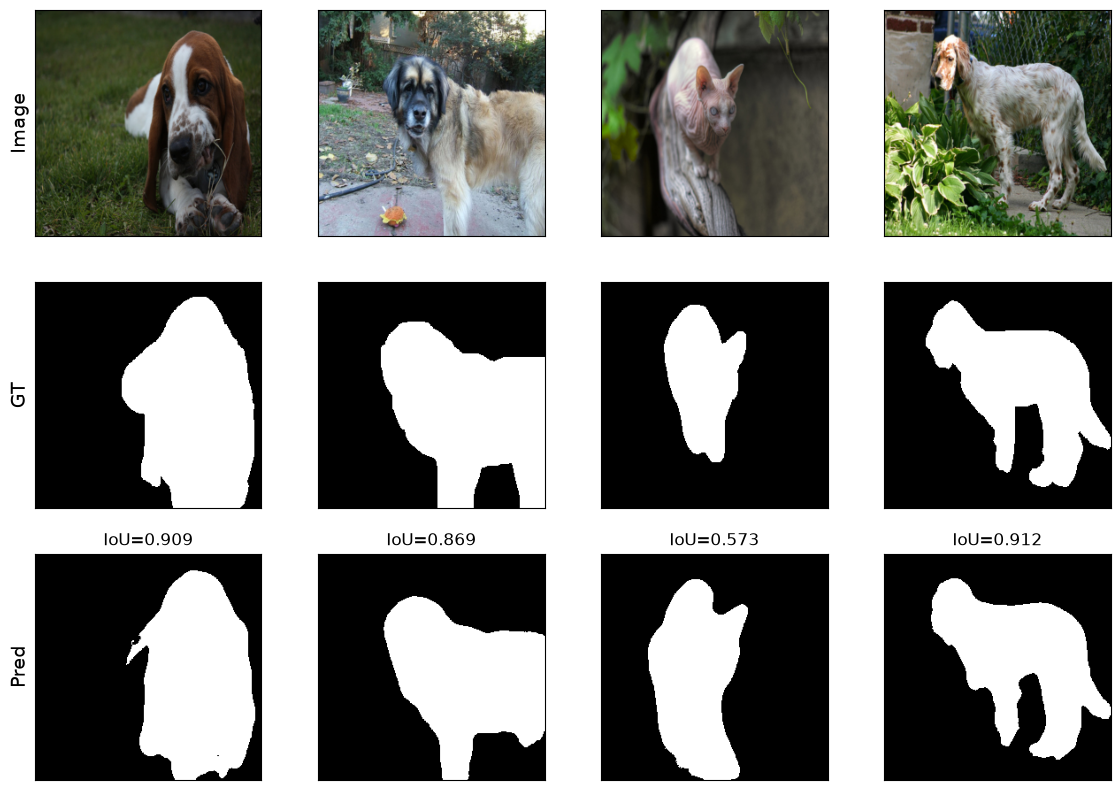

In [14]:
images, masks = next(iter(val_loader))
model.eval()
with torch.no_grad():
    preds = torch.sigmoid(model(images.to(device))).cpu()

mean, std = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axs = plt.subplots(3, 4, figsize=(14, 10))
for i in range(4):
    axs[0, i].imshow((images[i] * std + mean).permute(1, 2, 0).clamp(0, 1))
    axs[1, i].imshow(masks[i, 0], cmap="gray")
    axs[2, i].imshow(preds[i, 0] > 0.5, cmap="gray")
    axs[2, i].set_title(f"IoU={iou_score(preds[i, 0], masks[i, 0]):.3f}")
for ax, label in zip(axs[:, 0], ["Image", "GT", "Pred"]):
    ax.set_ylabel(label, fontsize=14)
for ax in axs.flat:
    ax.set_xticks([])
    ax.set_yticks([])